In [ ]:
from pathlib import Path
import anndata as ad

data_dir = Path("/work/magroup/skrieger/Syndri/data/xenium_noise_experiment")
files = sorted(data_dir.glob("GSM950*_1pct.h5ad"))

# for path in files:
#     adata = ad.read_h5ad(path)

#     if "admix_probs_optimized_unexpressedgenes_withquerycelltype_0" not in adata.layers:
#         print(f"missing source layer: {path.name}")
#         continue

#     adata.layers["admix_probs_optimized_unexpressedgenes_withquerycelltype_X"] = (
#         adata.layers["admix_probs_optimized_unexpressedgenes_withquerycelltype_0"].copy()
#     )
#     del adata.layers["admix_probs_optimized_unexpressedgenes_withquerycelltype_0"]

#     adata.write_h5ad(path)
#     print(f"renamed layer in {path.name}")

missing source layer: GSM9509156_breast_breast_B17_B17_rctd_annotated_dropout_1pct.h5ad
missing source layer: GSM9509157_breast_breast_B16_B16_rctd_annotated_dropout_1pct.h5ad


KeyboardInterrupt: 

In [5]:
adata = ad.read_h5ad('/work/magroup/shared/tissueFM/processed_data/zhuang/scfm/pretrain/0.h5ad')
adata.obs['cell_label']

237969407200283353425343368802596655973    237969407200283353425343368802596655973
112732736601068885348393944654633454474    112732736601068885348393944654633454474
117750215352927249265215787923412342338    117750215352927249265215787923412342338
119762943164481505976979859358490769206    119762943164481505976979859358490769206
121008072809942138107320330714923010875    121008072809942138107320330714923010875
                                                            ...                   
297209407269778071108946499038127298664    297209407269778071108946499038127298664
302172096957943182136477338762842553829                                        nan
317816278265681966681044964291699028175                                        nan
334226335185227821419833937751823896818    334226335185227821419833937751823896818
94658190611442534849529066729546741422                                         nan
Name: cell_label, Length: 26020, dtype: category
Categories (25766, str): ['21037989137

In [22]:
import os
adata = ad.read_h5ad(os.path.join(data_dir,files[1]))


In [ ]:
import seaborn as sns


In [71]:
pvals = adata.layers['admix_probs_matchedcelltypes_optimized_X'].toarray().ravel()
counts = adata.X.toarray().ravel()
tot = len(pvals[counts>0])
num = len(pvals[(pvals>0.95)])
print(num/tot)

0.4813082648534445


0.9465419054031372


<Axes: ylabel='Count'>

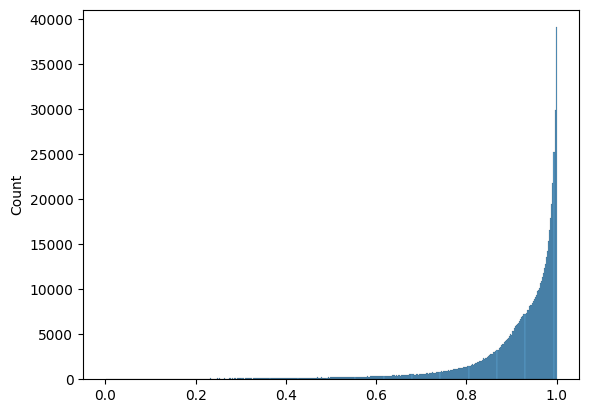

In [ ]:
import numpy as np
pvals = adata.layers['admix_probs_matchedcelltypes_optimized_X'].toarray().ravel()
counts = adata.X.toarray().ravel()

pvals = pvals[counts>0]
print(np.percentile(pvals,50))
sns.histplot(x=pvals)

In [76]:
from umap import UMAP
import scanpy as sc
from sklearn.decomposition import PCA
counts = adata.X.toarray()

pvals = adata.layers['admix_probs_trial_0'].toarray()

# counts[pvals>0.95] = (1-pvals[pvals>0.95])*counts[pvals>0.95]
counts[pvals>0.95] = 0

counts = (counts-np.mean(counts,axis=0))/(np.std(counts,axis=0))

pcs = PCA(n_components=30).fit_transform(counts)

coords = UMAP(n_components=2).fit_transform(pcs) 

adata.obsm['UMAP_cleaned'] = coords

In [77]:
from umap import UMAP
import scanpy as sc
from sklearn.decomposition import PCA
counts = adata.X.toarray()

pvals = adata.layers['admix_probs_matchedcelltypes_optimized_X'].toarray()

# counts[pvals>0.99] = 0

counts = (counts-np.mean(counts,axis=0))/(np.std(counts,axis=0))

pcs = PCA(n_components=30).fit_transform(counts)

coords = UMAP(n_components=2).fit_transform(pcs) 

adata.obsm['UMAP_raw'] = coords

Text(0.5, 1.0, 'Cleaned (pval>0.95 set to 0)')

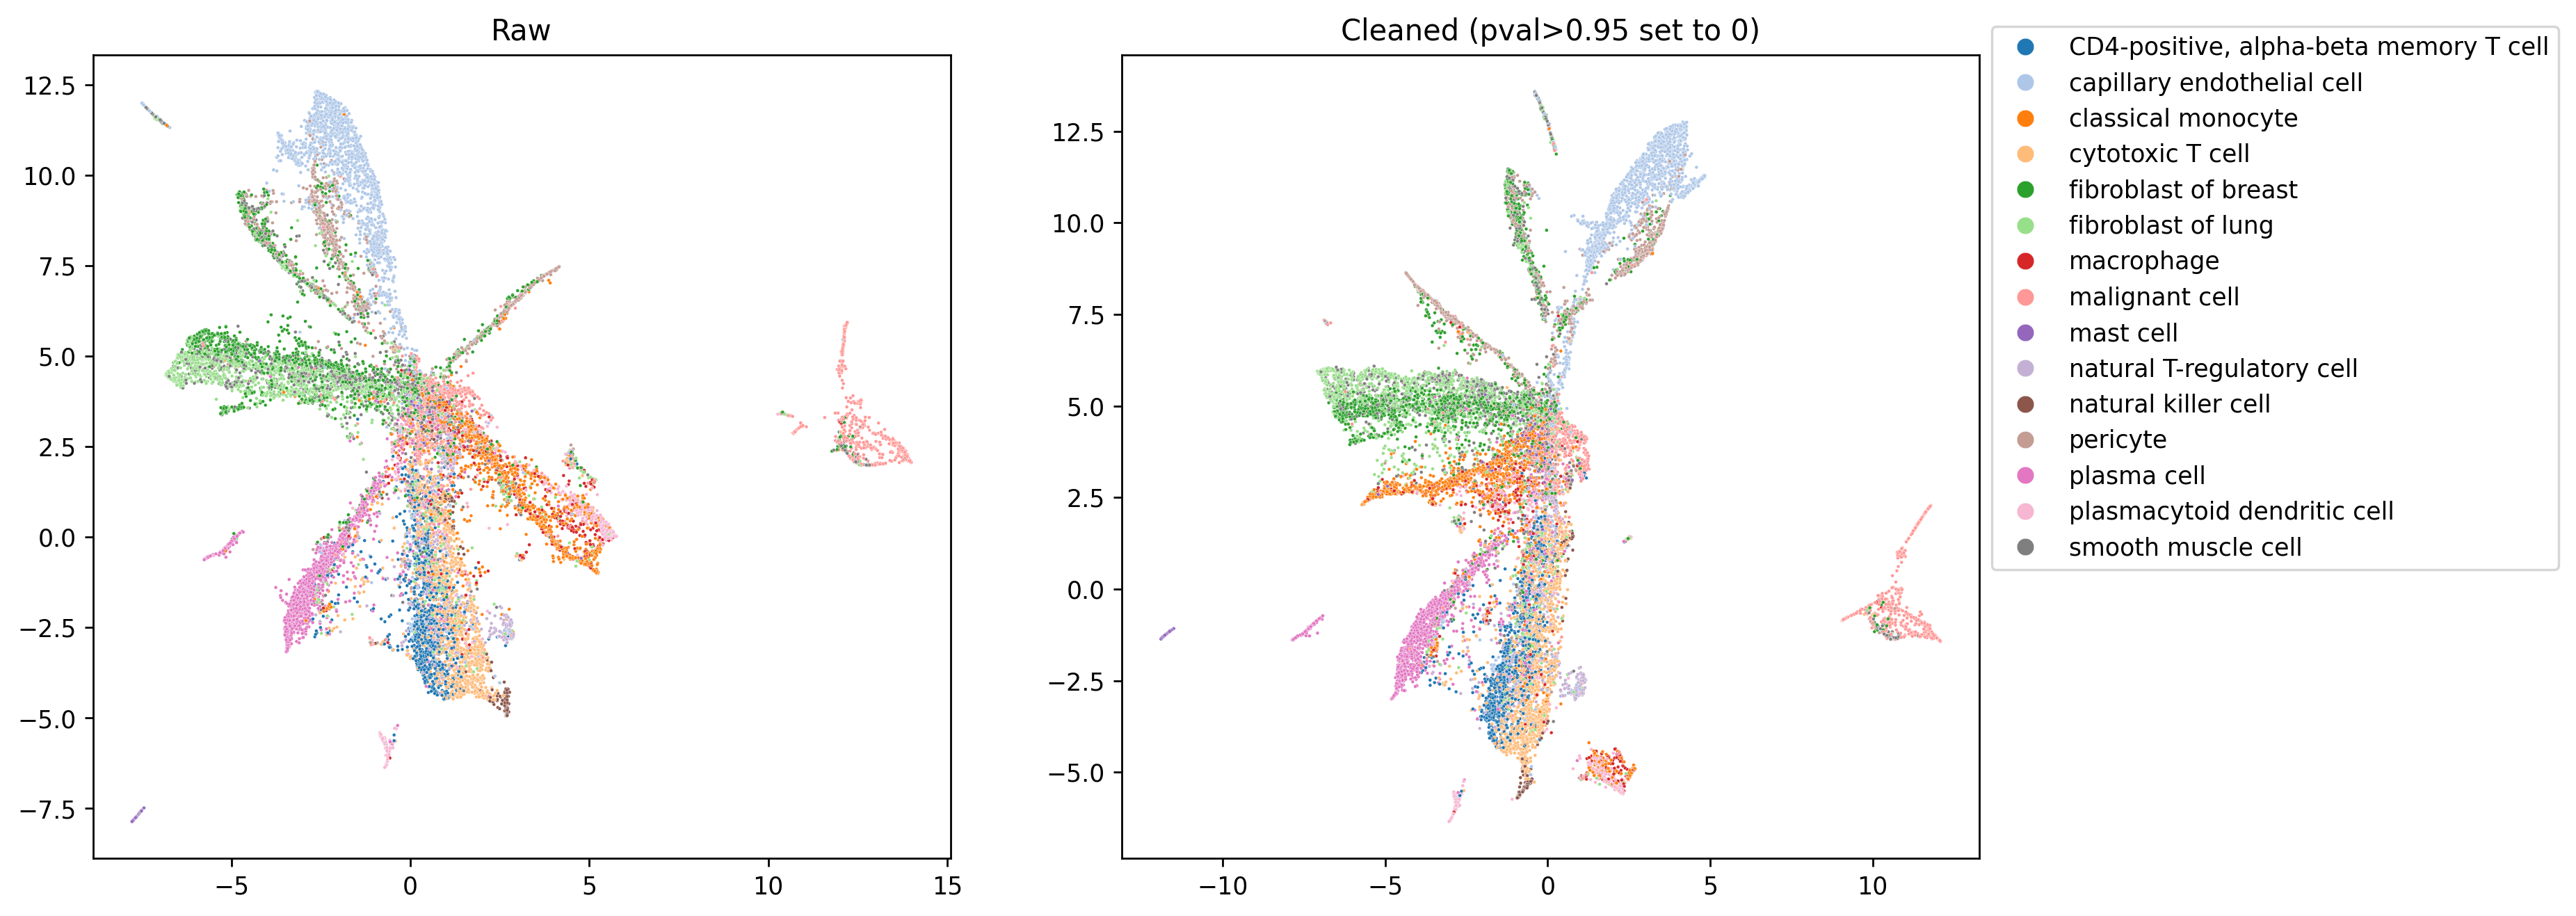

In [84]:
import matplotlib.pyplot as plt

fig,axes = plt.subplots(nrows=1,ncols=2,figsize=(14,6),dpi=250)

ax = axes[0]
ax = sns.scatterplot(x=adata.obsm['UMAP_raw'][:,0],y=adata.obsm['UMAP_raw'][:,1],hue=adata.obs['harmony_cell_type'],palette='tab20',s=2,ax=ax,legend=False)
ax.set_title('Raw')

ax = axes[1]
ax = sns.scatterplot(x=adata.obsm['UMAP_cleaned'][:,0],y=adata.obsm['UMAP_cleaned'][:,1],hue=adata.obs['harmony_cell_type'],palette='tab20',s=2,ax=ax)
ax.legend(bbox_to_anchor=(1,1.05),markerscale=5)
ax.set_title('Cleaned (pval>0.95 set to 0)')